In [1]:
import pandas as pd
import seaborn as sns

import plateau_analysis as pa
import subsampling_plots as sp

DATA_DIR = '../data'
N = 18  # for all image sets the number of stimuli was 18

# the image set colours live with the other figure settings, in subsampling_plots
palette_imset = sp.PALETTE_IMAGE_SET

# Arial and a light grey frame as in the reliability and embedding figures, but no grid,
# which looks odd on the log scale of the subsampling figures
sns.set_style('whitegrid', {'axes.grid': False})
sns.set_context('notebook')

In [2]:
# The simulations were saved in separate files per condition and per batch of
# random runs (10 + 50 + 40 = 100 runs per condition), because holding them all
# at once ran into memory limits. The loader globs those files back together.
df_subsampling = pa.load_subsampling_runs(DATA_DIR)
df_subsampling

,random-run,n,d,accuracy,observer,task,image_set
0,0,28,1,0.547373,P1,classic,action
1,1,28,1,0.626810,P1,classic,action
2,2,28,1,0.731072,P1,classic,action
3,3,28,5,0.538271,P1,classic,action
4,4,28,5,0.592884,P1,classic,action
...,...,...,...,...,...,...,...
8395,45,1800,3,0.917969,P2,odd one out,taxonomic
8396,46,1800,2,0.915625,P2,odd one out,taxonomic
8397,47,1800,3,0.926562,P2,odd one out,taxonomic
8398,48,1800,2,0.915625,P2,odd one out,taxonomic


In [3]:
# reference embeddings fitted on the complete triplet set: they carry the
# dimensionality and the ceiling accuracy of every condition
df_embeddings = pa.load_reference_embeddings(DATA_DIR)
df_embeddings['random-run'] = 0
df_embeddings

,observer,task,image_set,d,accuracy,n,random-run
0,P1,classic,action,2,0.919836,2445,0
1,P1,classic,greebles,2,0.782752,2435,0
2,P1,classic,taxonomic,2,0.935961,2436,0
3,P1,odd one out,action,2,0.987127,2447,0
4,P1,odd one out,greebles,1,0.845209,2442,0
5,P1,odd one out,taxonomic,1,0.996935,2447,0
6,P2,classic,action,2,0.822686,2442,0
7,P2,classic,greebles,2,0.841237,2425,0
8,P2,classic,taxonomic,3,0.883149,2439,0
9,P2,odd one out,action,1,0.850765,2419,0


In [4]:
df_subsampling[df_subsampling['task'] == 'classic']['n'].min()

28

In [5]:
df_subsampling[df_subsampling['task'] == 'classic']['n'].max()

1800

In [6]:
# Plateau analysis.
# Computed here, BEFORE the complete data set rows are merged into
# df_subsampling in the next cell. The complete set embedding is evaluated
# in-sample, whereas every sub-sampled embedding is evaluated on held-out
# triplets, so the two accuracies are not on the same scale and the complete
# set must not enter the gain computation. It serves only as a ceiling.
PLATEAU_THRESHOLD_PP = 1.0

# keep a copy of the sub-sample grid alone, for the sensitivity analysis below
df_runs = df_subsampling.copy()

plateau = pa.plateau_table(df_runs, df_embeddings,
                           threshold_pp=PLATEAU_THRESHOLD_PP, n_stimuli=N)
plateau_by_condition = pa.plateau_lookup(plateau)

plateau[['observer', 'task', 'image_set', 'd',
         'bound_triplets', 'bound_trials',
         'plateau_trials', 'ratio_to_bound',
         'accuracy_at_plateau', 'ceiling_accuracy']].round(2)


,observer,task,image_set,d,bound_triplets,bound_trials,plateau_trials,ratio_to_bound,accuracy_at_plateau,ceiling_accuracy
0,P1,classic,action,2,104,104.0,NaN,NaN,NaN,91.98
1,P1,classic,greebles,2,104,104.0,NaN,NaN,NaN,78.28
2,P1,classic,taxonomic,2,104,104.0,NaN,NaN,NaN,93.60
3,P1,odd one out,action,2,104,52.0,225.0,4.33,96.85,98.71
4,P1,odd one out,greebles,1,52,26.0,450.0,17.31,83.12,84.52
5,P1,odd one out,taxonomic,1,52,26.0,450.0,17.31,99.10,99.69
6,P2,classic,action,2,104,104.0,NaN,NaN,NaN,82.27
7,P2,classic,greebles,2,104,104.0,NaN,NaN,NaN,84.12
8,P2,classic,taxonomic,3,156,156.0,NaN,NaN,NaN,88.31
9,P2,odd one out,action,1,52,26.0,225.0,8.65,83.59,85.08


In [7]:
# merge subsampling with full set 
df_subsampling = pd.concat((df_subsampling, df_embeddings))


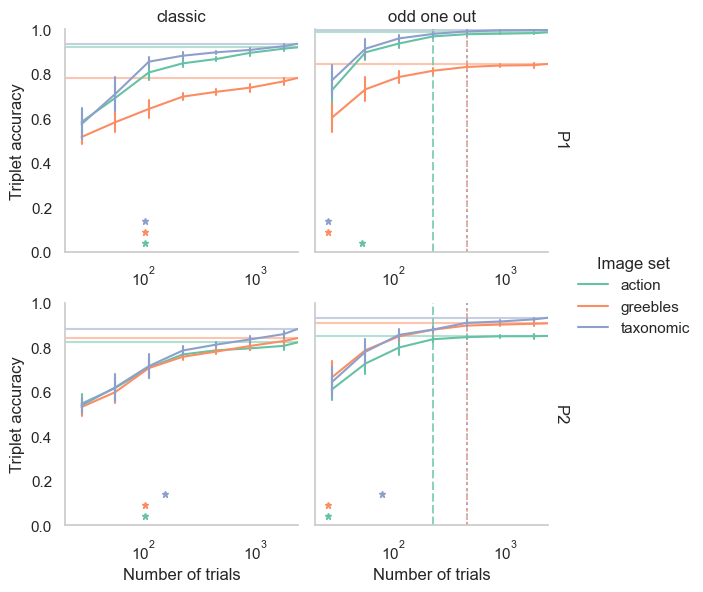

In [8]:
g = sns.FacetGrid(data=df_subsampling, hue='image_set', col="task", row='observer',
                  sharex=False, ylim=(0.0, 1.0), col_order = ['classic', 'odd one out'],
                  xlim=(20, 2400),
                  margin_titles=True,
                  palette=palette_imset)

g.map(sns.lineplot, 'n', 'accuracy', errorbar='sd', markers=True, err_style = "bars")

for (obs, task), ax in g.axes_dict.items():
    ax.set_xscale('log')
    for j, imset in enumerate(palette_imset):
        ref = pa.reference_row(df_embeddings, obs, task, imset)
        color = palette_imset[imset]

        # the bound counts triplet comparisons, the abscissa counts trials,
        # so it must be converted before it is drawn
        bound_trials, _ = pa.bound_interval_trials(N, int(ref['d']), task)
        sp.draw_bound_marker(ax, bound_trials, y=0.04 + j * 0.05, color=color)

        # vertical line at the plateau, drawn only where the criterion was met
        sp.draw_plateau_line(ax, plateau_by_condition[(obs, task, imset)],
                             color=color, image_set=imset)

        # horizontal line with max triplet accuracy
        sp.draw_ceiling_line(ax, ref['accuracy'], color=color, xmin=20, xmax=2400)


g.add_legend(title = 'Image set')
g.set_ylabels('Triplet accuracy')
g.set_xlabels('Number of trials')
g.set_titles(row_template="{row_name}", col_template="{col_name}")
g.savefig('../plots/subsampling_P1_P2.pdf')

In [9]:
sp.add_obs_task_column(df_subsampling)

,random-run,n,d,accuracy,observer,task,image_set,obs-task
0,0,28,1,0.547373,P1,classic,action,P1 - classic
1,1,28,1,0.626810,P1,classic,action,P1 - classic
2,2,28,1,0.731072,P1,classic,action,P1 - classic
3,3,28,5,0.538271,P1,classic,action,P1 - classic
4,4,28,5,0.592884,P1,classic,action,P1 - classic
...,...,...,...,...,...,...,...,...
7,0,2425,2,0.841237,P2,classic,greebles,P2 - classic
8,0,2439,3,0.883149,P2,classic,taxonomic,P2 - classic
9,0,2419,1,0.850765,P2,odd one out,action,P2 - odd one out
10,0,2424,1,0.907384,P2,odd one out,greebles,P2 - odd one out


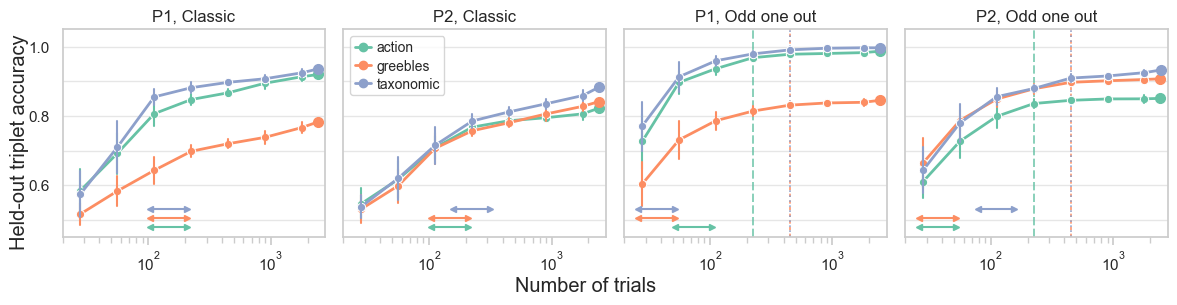

In [10]:
g = sns.FacetGrid(data=df_subsampling, hue='image_set', col="obs-task",
                  sharex=False,
                  xlim=(20, 2800),
                  ylim=(0.45, 1.05),
                  margin_titles=True,
                  height=3,
                  palette=palette_imset,
                  despine=False,
                  col_order = ['P1 - classic', 'P2 - classic', 'P1 - odd one out', 'P2 - odd one out'])

g.map(sns.lineplot, 'n', 'accuracy', errorbar='sd', err_style = "bars", linewidth=2, marker='o', markers=True, markersize=6)


for obs_task, ax in g.axes_dict.items():
    obs, task = sp.split_obs_task(obs_task)
    ax.set_xscale('log')
    for j, imset in enumerate(palette_imset):
        ref = pa.reference_row(df_embeddings, obs, task, imset)
        color = palette_imset[imset]
        ylevel = 0.48 + j * 0.025

        # the bound counts triplet comparisons, the abscissa counts trials,
        # so it must be converted before it is drawn
        sp.draw_bound_interval(ax, pa.bound_interval_trials(N, int(ref['d']), task),
                               y=ylevel, color=color)

        # vertical line at the plateau, drawn only where the criterion was met
        sp.draw_plateau_line(ax, plateau_by_condition[(obs, task, imset)],
                             color=color, image_set=imset)

        # the complete data set, as a ceiling marker rather than a curve point
        sp.draw_ceiling_point(ax, ref['n'], ref['accuracy'], color=color)


# in the empty upper left corner of the P2 classic panel, framed and without title
# as in the reliability figure
sp.place_legend_inside(g, panel=1, title=None, frameon=True, loc='upper left',
                       labelspacing=0.3, borderpad=0.3, handlelength=1.2, handletextpad=0.4)
g.set_ylabels('')
g.set_xlabels('')
for obs_task, ax in g.axes_dict.items():
    obs, task = sp.split_obs_task(obs_task)
    ax.set_title(f"{obs}, {task.capitalize()}")
    # horizontal grey lines every 0.1, labelled every 0.2 as in the reliability figure
    ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_yticklabels(['', '0.6', '', '0.8', '', '1.0'])
    ax.grid(axis='y', color='0.9')  # lighter than the panel border (0.8)
    # the whitegrid style hides tick marks; show them on the log axis, minor ones included,
    # in the grey of the panel border
    ax.tick_params(axis='x', which='both', bottom=True, color='0.8')
# tight_layout ignores the figure level labels: leave a margin on the left for the
# y label, and hang the x label just below the tick labels of the panels
g.tight_layout(rect=(0.02, 0, 1, 1))
g.fig.supylabel('Held-out triplet accuracy')
panels_bottom = min(ax.get_position().y0 for ax in g.axes.flat)
g.fig.supxlabel('Number of trials', y=panels_bottom - 0.13, va='top')
g.savefig('../plots/subsampling_P1_P2_v2.pdf')

In [11]:
summary_dimensionality = df_subsampling.groupby(['observer', 'task', 'image_set', 'n'])['d'].mean().reset_index()
summary_dimensionality['obs-task'] = summary_dimensionality['observer'] + ' - ' + summary_dimensionality['task'] 
summary_dimensionality

,observer,task,image_set,n,d,obs-task
0,P1,classic,action,28,2.36,P1 - classic
1,P1,classic,action,56,1.00,P1 - classic
2,P1,classic,action,112,1.00,P1 - classic
3,P1,classic,action,225,1.00,P1 - classic
4,P1,classic,action,450,1.03,P1 - classic
...,...,...,...,...,...,...
91,P2,odd one out,taxonomic,225,1.18,P2 - odd one out
92,P2,odd one out,taxonomic,450,1.81,P2 - odd one out
93,P2,odd one out,taxonomic,900,2.04,P2 - odd one out
94,P2,odd one out,taxonomic,1800,2.83,P2 - odd one out


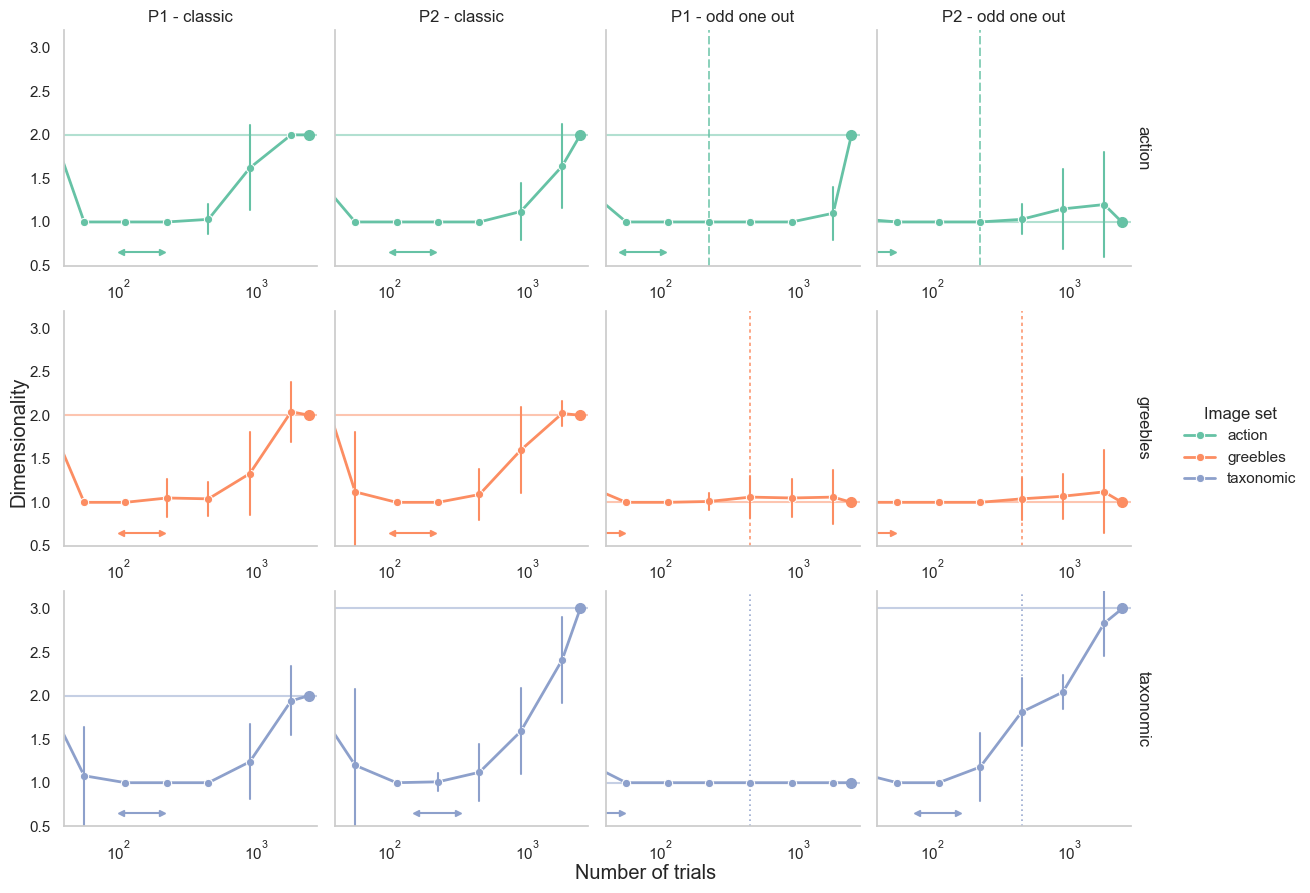

In [12]:
g = sns.FacetGrid(data=df_subsampling, hue='image_set', col="obs-task", row='image_set',
                  sharex=False,
                  ylim=(0.5, 3.2),
                  height=3,
                  xlim=(40, 2800),
                  margin_titles=True,
                  palette=palette_imset,
                  col_order = ['P1 - classic', 'P2 - classic', 'P1 - odd one out', 'P2 - odd one out'])

g.map(sns.lineplot, 'n', 'd', errorbar='sd', err_style = "bars", linewidth=2, marker='o', markers=True, markersize=6)

for (imset, obs_task), ax in g.axes_dict.items():
    obs, task = sp.split_obs_task(obs_task)
    ax.set_xscale('log')

    ref = pa.reference_row(df_embeddings, obs, task, imset)
    color = palette_imset[imset]
    d = int(ref['d'])

    # dimensionality of the complete data set embedding, as point and level
    sp.draw_ceiling_point(ax, ref['n'], d, color=color)
    sp.draw_ceiling_line(ax, d, color=color, xmin=40, xmax=2800)

    # vertical line at the plateau of the accuracy curve, for reference
    sp.draw_plateau_line(ax, plateau_by_condition[(obs, task, imset)],
                         color=color, image_set=imset)

    ylevel = 0.65  # for the arrows
    # the bound counts triplet comparisons, the abscissa counts trials,
    # so it must be converted before it is drawn
    sp.draw_bound_interval(ax, pa.bound_interval_trials(N, d, task),
                           y=ylevel, color=color)


g.add_legend(title = 'Image set')
g.set_ylabels('Dimensionality')
g.set_xlabels('')
g.fig.supxlabel('Number of trials')
g.set_ylabels('')
g.fig.supylabel('Dimensionality')
g.set_titles(row_template="{row_name}", col_template="{col_name}")
g.savefig('../plots/subsampling_P1_P2_dim.pdf')

In [13]:
# The numbers quoted in the Results section.
reached = plateau[plateau['plateau_reached']]

print('minimum plateau across conditions :', reached['plateau_trials'].min(), 'trials')
print('minimum ratio to the bound        :', round(reached['ratio_to_bound'].min(), 2))
print('conditions without a plateau      :', (~plateau['plateau_reached']).sum(), 'of', len(plateau))
print()
print('plateau per task:')
print(reached.groupby('task')['plateau_trials'].agg(['min', 'max']))


minimum plateau across conditions : 225.0 trials
minimum ratio to the bound        : 4.33
conditions without a plateau      : 6 of 12

plateau per task:
               min    max
task                     
odd one out  225.0  450.0


In [14]:
# Sensitivity of the plateau to the criterion, for the Supplementary Material.
sensitivity = pa.sensitivity_table(df_runs, df_embeddings,
                     thresholds_pp=[0.5, 1.0, 2.0], n_stimuli=N)

sensitivity

threshold_pp                      0.5    1.0    2.0
observer task        image_set                     
P1       classic     action       NaN    NaN  900.0
                     greebles     NaN    NaN    NaN
                     taxonomic    NaN    NaN  225.0
         odd one out action     450.0  225.0  225.0
                     greebles   900.0  450.0  225.0
                     taxonomic  450.0  450.0  112.0
P2       classic     action       NaN    NaN  225.0
                     greebles     NaN    NaN    NaN
                     taxonomic    NaN    NaN    NaN
         odd one out action     450.0  225.0  225.0
                     greebles   450.0  450.0  225.0
                     taxonomic    NaN  450.0  450.0

In [15]:
# Export the plateau table as LaTeX.
latex = pa.plateau_table_to_latex(plateau, threshold_pp=PLATEAU_THRESHOLD_PP)
print(latex)


\begin{table}[htbp]
    \centering
    \begin{tabular}{llrrrrr}
        \hline
        Obs. & Image set & $d$ & Bound & Bound & Plateau & Plateau \\
         &  &  & (triplets) & (trials) & (trials) & / bound \\
        \hline
        \multicolumn{7}{l}{\textit{classic}} \\
        P1 & action & 2 & 104 & 104 & $> 1800$ & $> 17.3$ \\
        P1 & greebles & 2 & 104 & 104 & $> 1800$ & $> 17.3$ \\
        P1 & taxonomic & 2 & 104 & 104 & $> 1800$ & $> 17.3$ \\
        P2 & action & 2 & 104 & 104 & $> 1800$ & $> 17.3$ \\
        P2 & greebles & 2 & 104 & 104 & $> 1800$ & $> 17.3$ \\
        P2 & taxonomic & 3 & 156 & 156 & $> 1800$ & $> 11.5$ \\
        \hline
        \multicolumn{7}{l}{\textit{odd one out}} \\
        P1 & action & 2 & 104 & 52 & 225 & 4.3 \\
        P1 & greebles & 1 & 52 & 26 & 450 & 17.3 \\
        P1 & taxonomic & 1 & 52 & 26 & 450 & 17.3 \\
        P2 & action & 1 & 52 & 26 & 225 & 8.7 \\
        P2 & greebles & 1 & 52 & 26 & 450 & 17.3 \\
        P2 & taxonomic & 3

In [16]:
# Export the sensitivity table as LaTeX, for the Supplementary Material.
latex = pa.sensitivity_table_to_latex(sensitivity, largest_sample=plateau['largest_sample'].max())
print(latex)

\begin{table}[htbp]
    \centering
    \begin{tabular}{llrrr}
        \hline
         &  & \multicolumn{3}{c}{Plateau (trials) at threshold} \\
        Obs. & Image set & 0.5 pp & 1.0 pp & 2.0 pp \\
        \hline
        \multicolumn{5}{l}{\textit{classic}} \\
        P1 & action & $> 1800$ & $> 1800$ & 900 \\
        P1 & greebles & $> 1800$ & $> 1800$ & $> 1800$ \\
        P1 & taxonomic & $> 1800$ & $> 1800$ & 225 \\
        P2 & action & $> 1800$ & $> 1800$ & 225 \\
        P2 & greebles & $> 1800$ & $> 1800$ & $> 1800$ \\
        P2 & taxonomic & $> 1800$ & $> 1800$ & $> 1800$ \\
        \hline
        \multicolumn{5}{l}{\textit{odd one out}} \\
        P1 & action & 450 & 225 & 225 \\
        P1 & greebles & 900 & 450 & 225 \\
        P1 & taxonomic & 450 & 450 & 112 \\
        P2 & action & 450 & 225 & 225 \\
        P2 & greebles & 450 & 450 & 225 \\
        P2 & taxonomic & $> 1800$ & 450 & 450 \\
        \hline
    \end{tabular}
    \caption{Sample size at which triplet accu

In [17]:
df_subsampling['n'].max()

2447